# Exploratory Analysis

Welcome now, after the full diagnosis of our data, I would like to explore a little bit on the data and answer this questions using graphics:

* What is the distribution of the target variable?

* Is there any grade difference between dropout and graduate students?

* Does age affect on dropout?

* Do special educational needs affect student dropout?

* Which gender has a higher dropout rate?

* Does receiving a scholarship affect student dropout?

* Does keeping tuition fees up to date affect student dropout?

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
DATA_PATH = "../data/raw/dataset.csv"
df = pd.read_csv(DATA_PATH)

### ***What is the distribution of the target variable?***

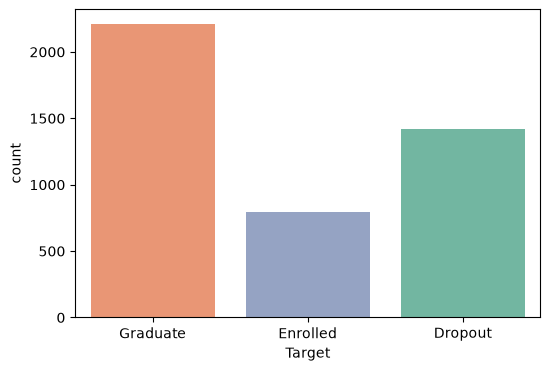

In [6]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Target",
    palette="Set2",
    hue="Target",
    order=["Graduate","Enrolled","Dropout"]
)

plt.show()

In this graphic we can confirm the difference between graduate and dropout elements in our dataset. We have more graduates student (around 30% more)

### ***Is there any grade difference between dropout and graduate students?***

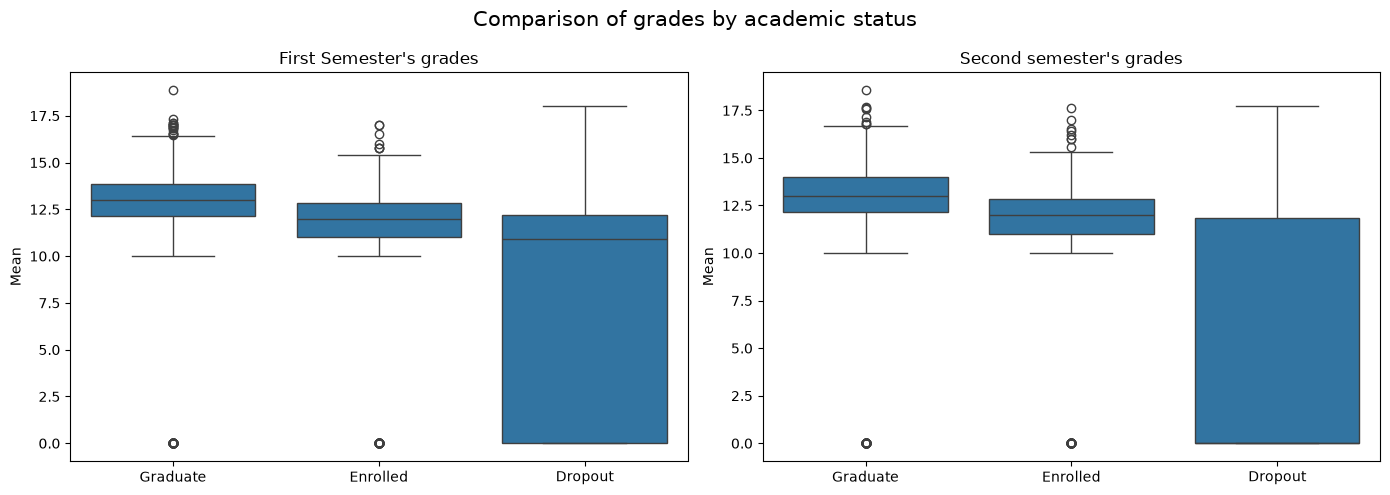

In [7]:

fig, ax = plt.subplots(1, 2, figsize=(14,5))

# First semester
sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (grade)",
    order=["Graduate", "Enrolled", "Dropout"],
    ax=ax[0]
)

ax[0].set_title("First Semester's grades")
ax[0].set_xlabel("")
ax[0].set_ylabel("Mean")

# Second semester
sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 2nd sem (grade)",
    order=["Graduate", "Enrolled", "Dropout"],
    ax=ax[1]
)

ax[1].set_title("Second semester's grades")
ax[1].set_xlabel("")
ax[1].set_ylabel("Mean")

plt.suptitle("Comparison of grades by academic status", fontsize=15)

plt.tight_layout()
plt.show()

The visual analysis identifies academic performance as a highly discriminative feature for the dropout prediction framework. There is a robust correlation between higher mean grades and graduation throughput, suggesting this variable will yield high feature importance during model training.

### ***Does age affect on dropout?***

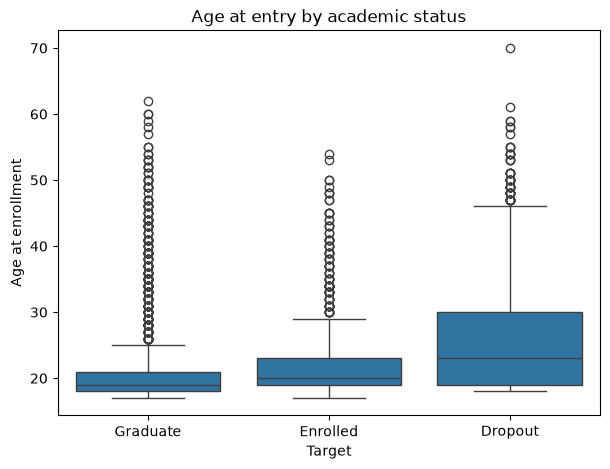

In [8]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x="Target",
    y="Age at enrollment",
    order=["Graduate","Enrolled","Dropout"]
)

plt.title("Age at entry by academic status")

plt.show()

Age at enrollment also emerges as a critical feature. The data indicates that younger students—specifically around 18 years old—exhibit higher graduation rates. Moving forward, evaluating the feature weights or SHAP values will be essential to determine how heavily the model relies on this demographic variable relative to financial factors.

### ***Do special educational needs affect student dropout?***

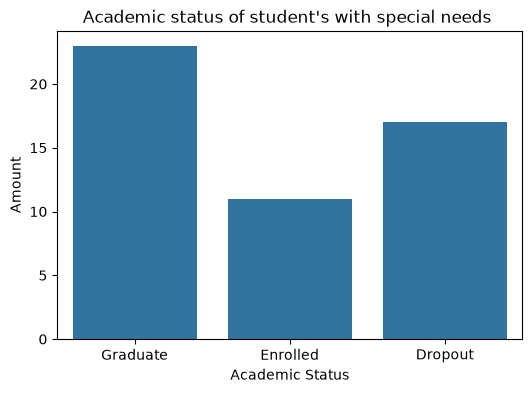

In [5]:
special = df[df["Educational special needs"] == 1]

plt.figure(figsize=(6,4))

sns.countplot(
    data=special,
    x="Target",
    order=["Graduate", "Enrolled", "Dropout"]
)

plt.title("Academic status of student's with special needs ")
plt.xlabel("Academic Status")
plt.ylabel("Amount")

plt.show()

Interestingly, students with special educational needs do not appear to have a substantially higher dropout rate. However, this group is considerably smaller than the rest of the dataset, so conclusions should be interpreted with caution.

### ***Which gender has a higher dropout rate?***

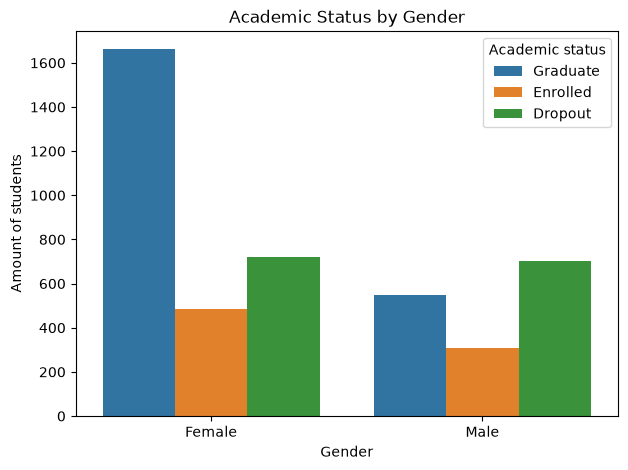

In [9]:
df["Gender_Label"] = df["Gender"].replace({
    0: "Female",
    1: "Male"
})

plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Gender_Label",
    hue="Target",
    order=["Female", "Male"],
    hue_order=["Graduate", "Enrolled", "Dropout"]
)

plt.title("Academic Status by Gender")
plt.xlabel("Gender")
plt.ylabel("Amount of students")

plt.legend(title="Academic status")

plt.show()

The first thing that we highlight is that we have much more data on women and also that men have a higher dropout rate than graduation rate. Let's do a final check with percentages.

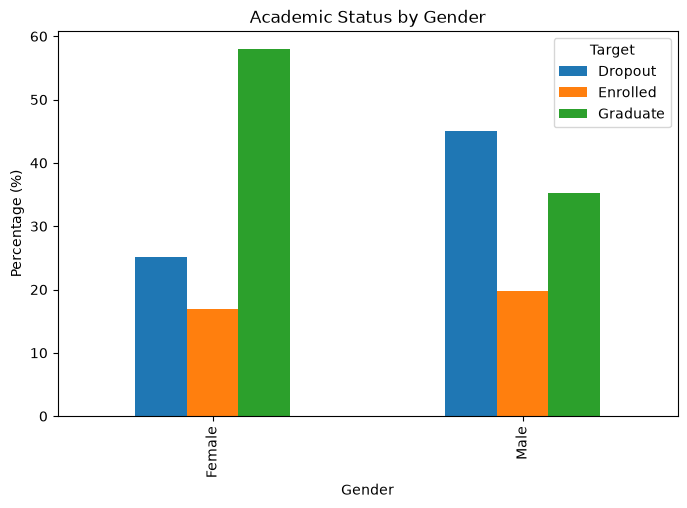

In [4]:
gender_percentage = (
    pd.crosstab(df["Gender"], df["Target"], normalize="index") * 100
)

gender_percentage.index = ["Female", "Male"]

gender_percentage.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Academic Status by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage (%)")
plt.legend(title="Target")

plt.show()

Female students have a higher graduation rate than male students, while male students show a higher proportion of dropouts. Although gender seems to have some relationship with the target variable, additional analysis is required to determine its predictive importance.

### ***Does receiving a scholarship affect student dropout?***

<Figure size 800x500 with 0 Axes>

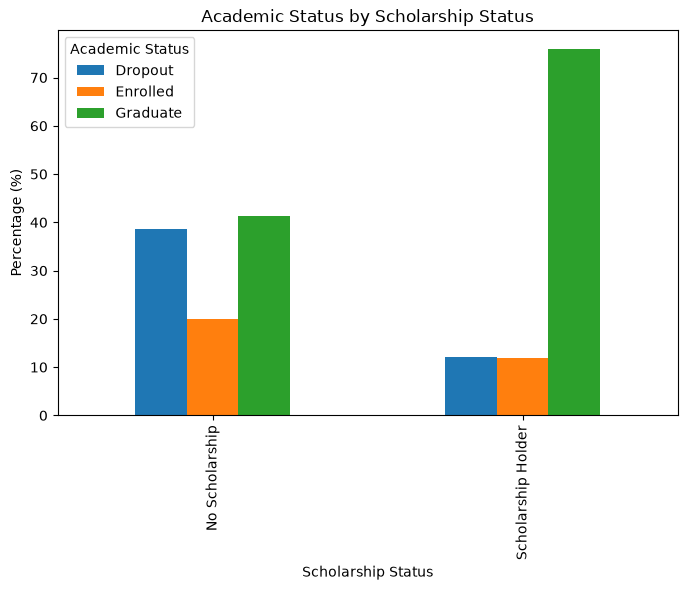

In [4]:
scholarship_percentage = (
    pd.crosstab(df["Scholarship holder"], df["Target"], normalize="index") * 100
)

scholarship_percentage.index = ["No Scholarship", "Scholarship Holder"]

scholarship_percentage.round(2)

plt.figure(figsize=(8,5))

scholarship_percentage.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Academic Status by Scholarship Status")
plt.xlabel("Scholarship Status")
plt.ylabel("Percentage (%)")
plt.legend(title="Academic Status")

plt.show()

Preliminary data indicates that over 70% of scholarship recipients successfully graduate. However, further statistical analysis is required to establish causality and properly integrate this feature into the predictive model.

### ***Does keeping tuition fees up to date affect student dropout?***

<Figure size 800x500 with 0 Axes>

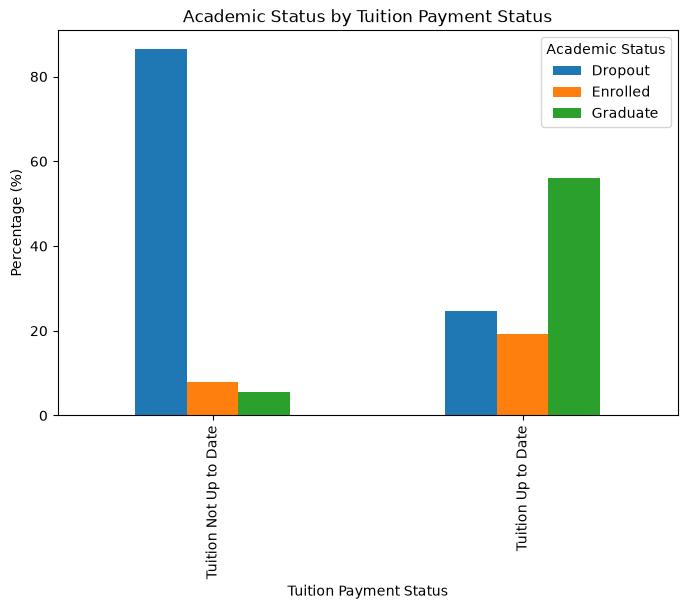

In [5]:
tuition_percentage = (
    pd.crosstab(df["Tuition fees up to date"], df["Target"], normalize="index") * 100
)

tuition_percentage.index = [
    "Tuition Not Up to Date",
    "Tuition Up to Date"
]

tuition_percentage.round(2)

plt.figure(figsize=(8,5))

tuition_percentage.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Academic Status by Tuition Payment Status")
plt.xlabel("Tuition Payment Status")
plt.ylabel("Percentage (%)")
plt.legend(title="Academic Status")

plt.show()

This variable emerges as a highly relevant feature for predicting student attrition. Notably, approximately 80% of students with outstanding tuition payments ultimately drop out.

The previous visualizations provide an initial understanding of the relationships between several variables and the target. Although these observations do not imply causation, they help identify potential predictors that may improve the performance of machine learning models.

## Conclusions

We explored some of the most interesting features and analyse how it would tend in the model. Honestly it helped me familiarize myself with the data. Now we are really to start with the real codification of the model. Thanks for reading the notebook.